**PRACTICAL LECTURE 3**

**PART1. Autoencoders**

**2025-2026**

1. Import libraries

In [4]:
import torch
import torchvision
from torch import nn
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import MNIST
from matplotlib import pyplot as plt
import numpy as np

2. Convert vector to image
The following function allows to convert a vector to an image

In [6]:
def to_img(x):
    x = 0.5 * (x + 1)
    x = x.view(x.size(0), 28, 28)
    return x

3. We now write a function which allows to display the images using the imshow() function.

In [7]:
def display_images(in_, out, n=1):
    for N in range(n):
        if in_ is not None:
            in_pic = to_img(in_.cpu().data)
            plt.figure(figsize=(18, 6))
            for i in range(4):
                plt.subplot(1,4,i+1)
                plt.imshow(in_pic[i+4*N])
                plt.axis('off')
        out_pic = to_img(out.cpu().data)
        plt.figure(figsize=(18, 6))
        for i in range(4):
            plt.subplot(1,4,i+1)
            plt.imshow(out_pic[i+4*N])
            plt.axis('off')

4. Define a data loading step and load the MNIST dataset (train and test sets).

In [8]:
batch_size = 256

img_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

dataset = MNIST('./data', transform=img_transform, download=True)
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True)

test_dataset = MNIST('./data', train=False, transform=img_transform, download=True)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

100%|██████████| 9.91M/9.91M [00:02<00:00, 3.97MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 342kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 2.70MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 2.02MB/s]


5. Fix the used device

In [9]:
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

6. Define the Autoencoder model architecture and reconstruction loss
with :
n = 28 x 28 = 784

A. Use d = 30  for standard AE (under-complete hidden layer)

B. Use d = 500 for denoising AE (over-complete hidden layer)

C. Compute **by hand** the number of parameters of the autoencoder for d = 30 and for d = 500, then check your answer with `sum(p.numel() for p in model.parameters())`.

D. Explain the difference between standard AE and denoising AE. Why would an over-complete standard AE (d = 500, no noise) be useless?
Analyse the results and conclude.

In [10]:
d=30

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(28 * 28, d),
            nn.Tanh(),
        )
        self.decoder = nn.Sequential(
            nn.Linear(d, 28 * 28),
            nn.Tanh(),
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

model = Autoencoder().to(device)
criterion = nn.MSELoss()

7. Configure the optimiser. We use here : learning_rate equals to 1e-3

In [11]:
learning_rate = 1e-3

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate,
)

8. Train the standard autoencoder and the denoising autoencoder using the following code :

epoch [1/20], loss:0.2107
epoch [2/20], loss:0.1498
epoch [3/20], loss:0.1226
epoch [4/20], loss:0.1004
epoch [5/20], loss:0.1018
epoch [6/20], loss:0.0934
epoch [7/20], loss:0.0880
epoch [8/20], loss:0.0813
epoch [9/20], loss:0.0805
epoch [10/20], loss:0.0704
epoch [11/20], loss:0.0677
epoch [12/20], loss:0.0710
epoch [13/20], loss:0.0713
epoch [14/20], loss:0.0624
epoch [15/20], loss:0.0588
epoch [16/20], loss:0.0681
epoch [17/20], loss:0.0533
epoch [18/20], loss:0.0537
epoch [19/20], loss:0.0542
epoch [20/20], loss:0.0600


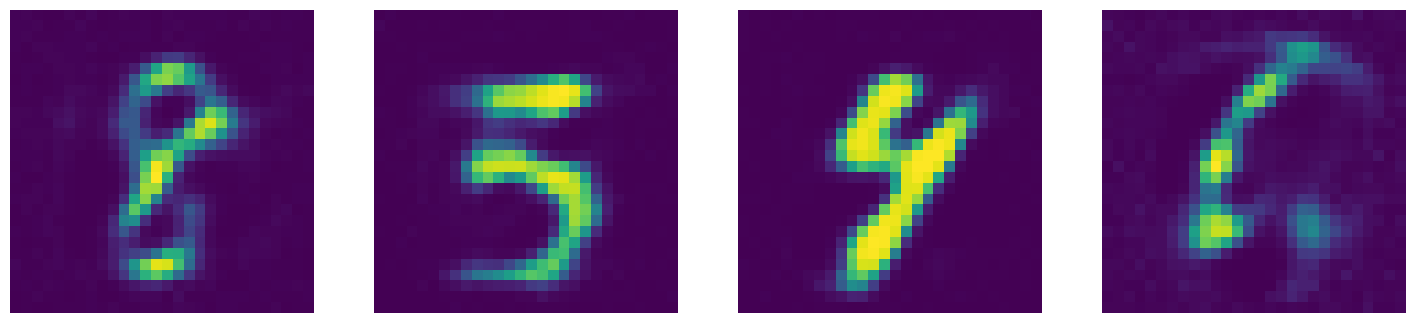

In [12]:
num_epochs = 20
# do = nn.Dropout()  # comment out for standard AE
for epoch in range(num_epochs):
    for data in dataloader:
        img, _ = data
        img = img.to(device)
        img = img.view(img.size(0), -1)
        # noise = do(torch.ones(img.shape)).to(device)
        # img_bad = (img * noise).to(device)  # comment out for standard AE
        # ===================forward=====================
        output = model(img)  # feed <img> (for std AE) or <img_bad> (for denoising AE)
        loss = criterion(output, img.data)
        # ===================backward====================
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    # ===================log========================
    print(f'epoch [{epoch + 1}/{num_epochs}], loss:{loss.item():.4f}')
display_images(None, output)  # pass (None, output) for std AE, (img_bad, output) for denoising AE

9. The Dropout noise above sets random pixels to zero. Write a second version of the denoising AE (d = 500) where the noise is **additive Gaussian noise** of standard deviation $\sigma = 0.5$ (be careful to keep the pixel values in $[-1, 1]$). Display noisy inputs and reconstructions, and compare with the Dropout version.

epoch [1/20], loss:0.0368
epoch [2/20], loss:0.0200
epoch [3/20], loss:0.0132
epoch [4/20], loss:0.0129
epoch [5/20], loss:0.0108
epoch [6/20], loss:0.0084
epoch [7/20], loss:0.0076
epoch [8/20], loss:0.0059
epoch [9/20], loss:0.0057
epoch [10/20], loss:0.0060
epoch [11/20], loss:0.0052
epoch [12/20], loss:0.0054
epoch [13/20], loss:0.0050
epoch [14/20], loss:0.0046
epoch [15/20], loss:0.0040
epoch [16/20], loss:0.0038
epoch [17/20], loss:0.0038
epoch [18/20], loss:0.0040
epoch [19/20], loss:0.0037
epoch [20/20], loss:0.0038


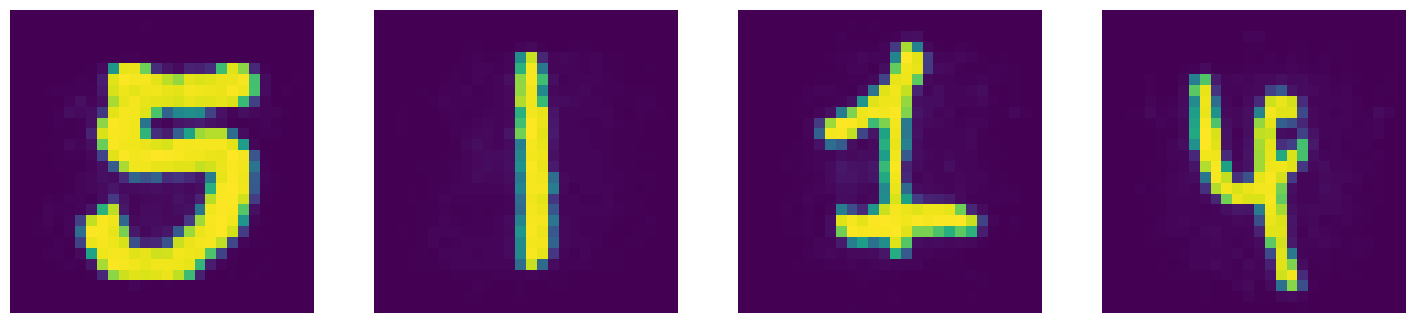

In [ ]:
d = 500
model = Autoencoder().to(device)
criterion = nn.MSELoss()
learning_rate = 1e-3

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate,
)
num_epochs = 20
# do = nn.Dropout()  # comment out for standard AE
for epoch in range(num_epochs):
    for data in dataloader:
        img, _ = data
        img = img.to(device)
        img = img.view(img.size(0), -1)

        # on remplace bruit dropout par gaussian
        noise = (torch.randn_like(img) * 0.5).to(device)
        # "additif"
        img_bad = img + noise
        # les valeurs de pixels doivent etre comprises entre -1 et 1
        img_bad = torch.clamp(img_bad, min = -1.0, max=1.0)
        
        # ===================forward=====================
        output = model(img)  # feed <img> (for std AE) or <img_bad> (for denoising AE)
        loss = criterion(output, img.data)
        # ===================backward====================
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    # ===================log========================
    print(f'epoch [{epoch + 1}/{num_epochs}], loss:{loss.item():.4f}')
display_images(None, output)  # pass (None, output) for std AE, (img_bad, output) for denoising AE

10. Visualise a few kernels of the encoder :

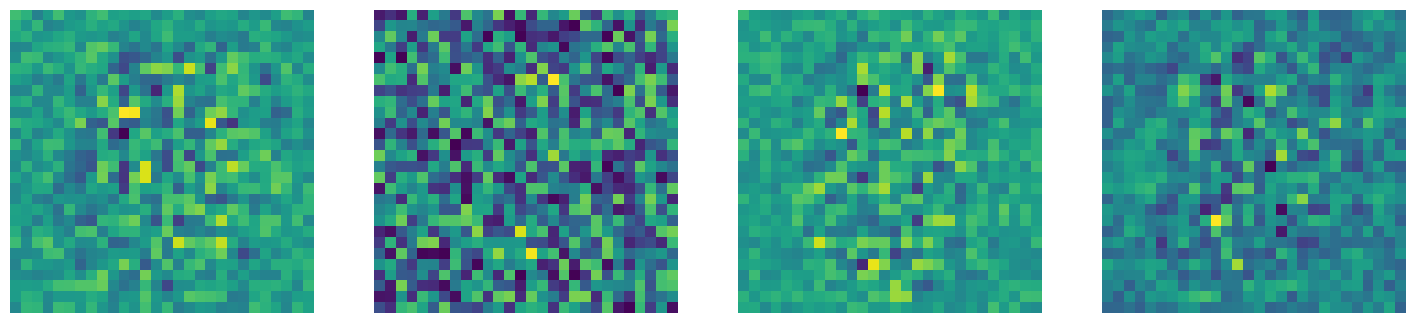

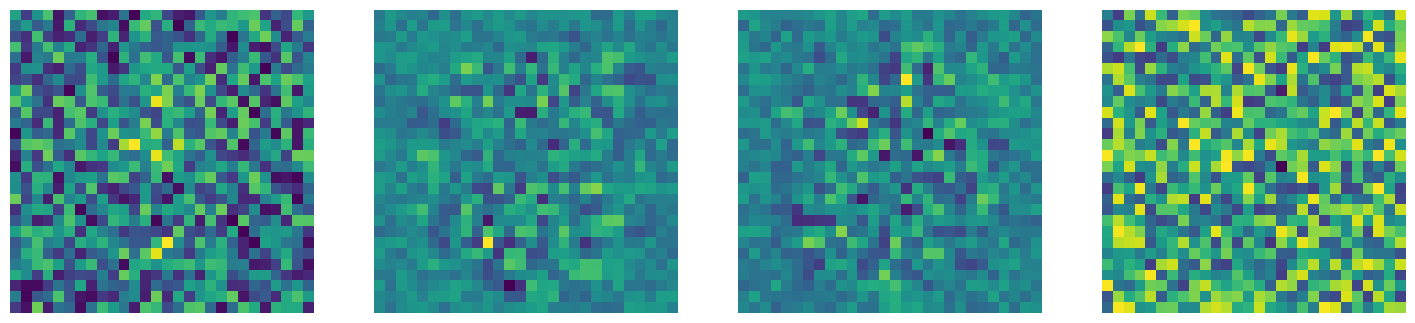

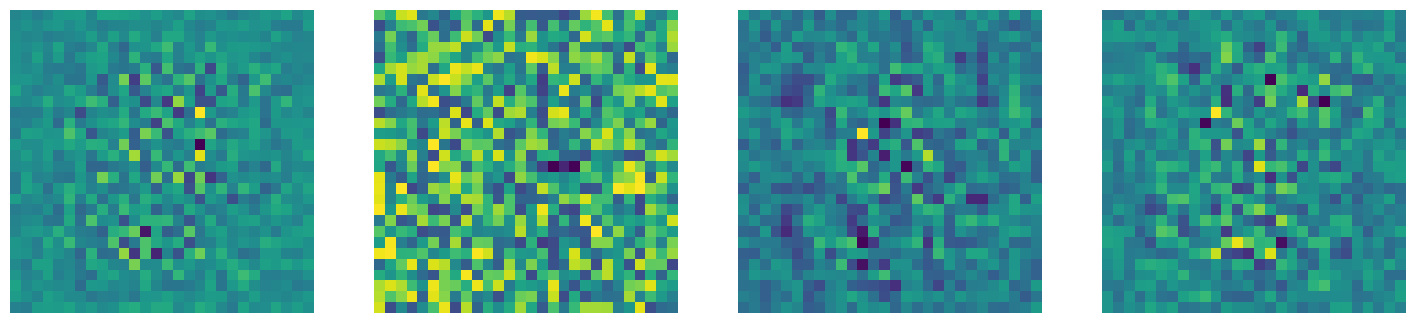

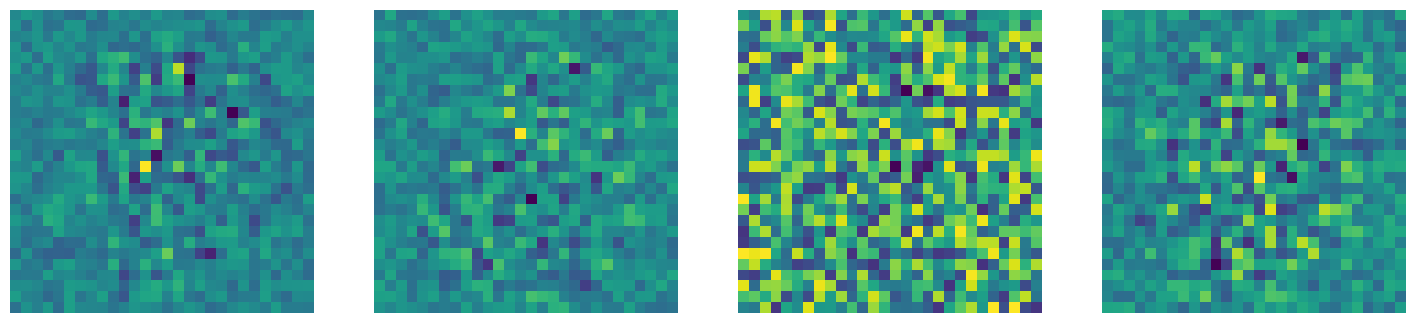

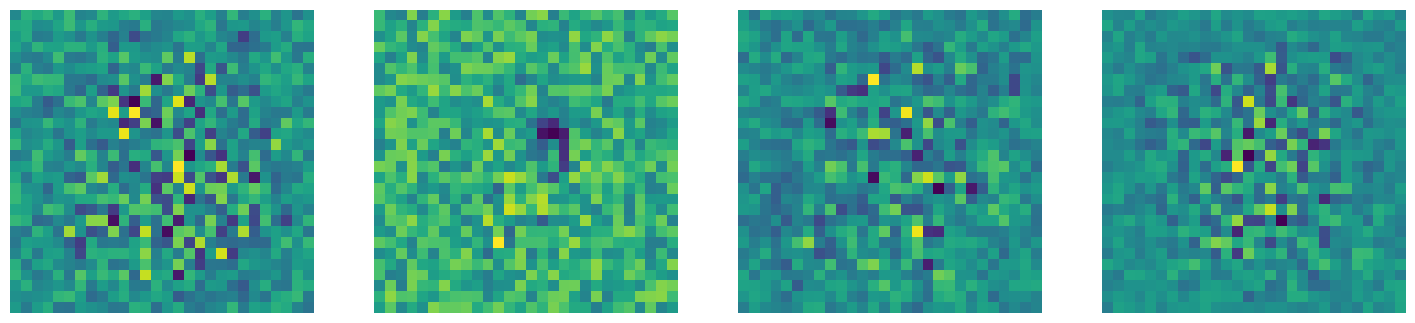

In [17]:
display_images(None, model.encoder[0].weight, 5)

11. Latent space. Train a standard autoencoder with **d = 2** (5 epochs are enough). Encode all the images of the test set and plot the 2-D codes as a scatter plot, with one color per digit (use the labels of `test_dataset`). Which digits are well separated? Which ones overlap? Is this surprising, given that the labels were never used during training?

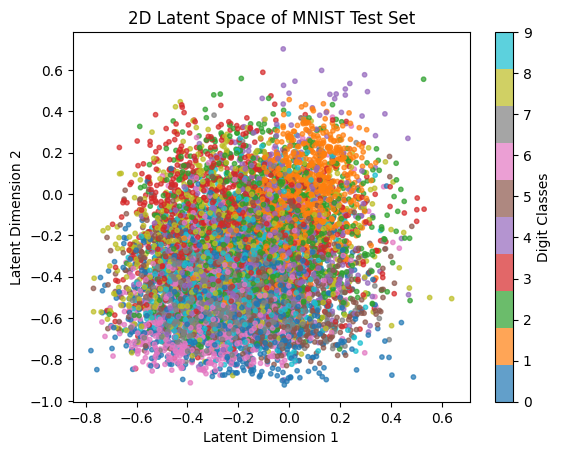

In [ ]:
d = 2
model_2d = Autoencoder().to(device)
criterion = nn.MSELoss()
learning_rate = 1e-3

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=learning_rate,
)

num_epochs = 5

model_2d.train()

for epoch in range(num_epochs):
    for data in dataloader:
        img, _ = data
        img = img.to(device)
        img = img.view(img.size(0), -1)
        
        output = model_2d(img)
        loss = criterion(output, img)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

latent_codes = []
labels_list = []

model_2d.eval()
with torch.no_grad(): # No need to track gradients for evaluation
    for data in test_dataloader:
        img, label = data
        img = img.to(device)
        img = img.view(img.size(0), -1)
        
        code = model_2d.encoder(img)
        latent_codes.append(code.cpu())
        labels_list.append(label) 
# on fusuonne les petits lots
latent_codes = torch.cat(latent_codes).numpy()
labels_list = torch.cat(labels_list).numpy()

plt.figure()
scatter = plt.scatter(latent_codes[:, 0], latent_codes[:, 1], c=labels_list, cmap='tab10', alpha=0.7, s=10)
plt.colorbar(scatter, ticks=range(10), label='Digit Classes')
plt.title("2D Latent Space of MNIST Test Set")
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.show()

12. Write a function `test_mse(model)` returning the mean reconstruction error on the **test set**. Train a standard AE (5 epochs each) for d ∈ {2, 10, 30, 100} and plot the test MSE as a function of d. Comment the curve.

13. Analyse the obtained results.

14. Change the parameters of the Autoencoder (activation functions, number of layers, learning rate…) and analyse their impact. Conclude.

**PART2. Convolutional Neural Networks**

1. Import the libraries and set the parameters

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np


def set_default(figsize=(10, 10), dpi=100):
    plt.style.use(['dark_background', 'bmh'])
    plt.rc('axes', facecolor='k')
    plt.rc('figure', facecolor='k')
    plt.rc('figure', figsize=figsize, dpi=dpi)

set_default()

# function to count number of parameters
def get_n_params(model):
    n = 0
    for p in list(model.parameters()):
        n += p.nelement()
    return n

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

2. Load the Dataset (MNIST) using PyTorch DataLoader utilities and visualize some images :

In [ ]:
input_size  = 28*28   # images are 28x28 pixels
output_size = 10      # there are 10 classes

train_loader = torch.utils.data.DataLoader(
    datasets.MNIST('../data', train=True, download=True,
                   transform=transforms.Compose([
                       transforms.ToTensor(),
                       transforms.Normalize((0.1307,), (0.3081,))
                   ])),
    batch_size=64, shuffle=True)

test_loader = torch.utils.data.DataLoader(
    datasets.MNIST('../data', train=False, transform=transforms.Compose([
                       transforms.ToTensor(),
                       transforms.Normalize((0.1307,), (0.3081,))
                   ])),
    batch_size=1000, shuffle=True)

plt.figure(figsize=(16, 6))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    image, _ = train_loader.dataset.__getitem__(i)
    plt.imshow(image.squeeze().numpy())
    plt.axis('off');

3. Create the model classes

In [ ]:
class FC2Layer(nn.Module):
    def __init__(self, input_size, n_hidden, output_size):
        super(FC2Layer, self).__init__()
        self.input_size = input_size
        self.network = nn.Sequential(
            nn.Linear(input_size, n_hidden),
            nn.ReLU(),
            nn.Linear(n_hidden, n_hidden),
            nn.ReLU(),
            nn.Linear(n_hidden, output_size),
            nn.LogSoftmax(dim=1)
        )

    def forward(self, x):
        x = x.view(-1, self.input_size)
        return self.network(x)

class CNN(nn.Module):
    def __init__(self, input_size, n_feature, output_size):
        super(CNN, self).__init__()
        self.n_feature = n_feature
        self.conv1 = nn.Conv2d(in_channels=1, out_channels=n_feature, kernel_size=5)
        self.conv2 = nn.Conv2d(n_feature, n_feature, kernel_size=5)
        self.fc1 = nn.Linear(n_feature*4*4, 50)
        self.fc2 = nn.Linear(50, 10)

    def forward(self, x, verbose=False):
        x = self.conv1(x)
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)
        x = self.conv2(x)
        x = F.relu(x)
        x = F.max_pool2d(x, kernel_size=2)
        x = x.view(-1, self.n_feature*4*4)
        x = self.fc1(x)
        x = F.relu(x)
        x = self.fc2(x)
        x = F.log_softmax(x, dim=1)
        return x

4. a. For an input image of size 1×28×28, compute **by hand** the shape of the tensor after each layer of the CNN (conv1, pooling, conv2, pooling). Justify the value `n_feature*4*4` used in `fc1`.

   b. Use the argument `verbose` of `forward` to print these shapes and check your answer.

   c. Compute by hand the number of parameters of the CNN for `n_feature = 6` and of the FC2Layer for `n_hidden = 8`. Check with `get_n_params`.

5. Run on a GPU: device string

Switching between CPU and GPU in PyTorch is controlled via a device string, which will seamlessly determine whether GPU is available, falling back to CPU if not:

In [ ]:
accuracy_list = []

def train(epoch, model, perm=torch.arange(0, 784).long()):
    model.train()
    for batch_idx, (data, target) in enumerate(train_loader):
        # send to device
        data, target = data.to(device), target.to(device)

        # permute pixels
        data = data.view(-1, 28*28)
        data = data[:, perm]
        data = data.view(-1, 1, 28, 28)

        optimizer.zero_grad()
        output = model(data)
        loss = F.nll_loss(output, target)
        loss.backward()
        optimizer.step()
        if batch_idx % 100 == 0:
            print('Train Epoch: {} [{}/{} ({:.0f}%)]\tLoss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), loss.item()))

def test(model, perm=torch.arange(0, 784).long()):
    model.eval()
    test_loss = 0
    correct = 0
    for data, target in test_loader:
        # send to device
        data, target = data.to(device), target.to(device)

        # permute pixels
        data = data.view(-1, 28*28)
        data = data[:, perm]
        data = data.view(-1, 1, 28, 28)
        output = model(data)
        test_loss += F.nll_loss(output, target, reduction='sum').item() # sum up batch loss
        pred = output.data.max(1, keepdim=True)[1] # get the index of the max log-probability
        correct += pred.eq(target.data.view_as(pred)).cpu().sum().item()

    test_loss /= len(test_loader.dataset)
    accuracy = 100. * correct / len(test_loader.dataset)
    accuracy_list.append(accuracy)
    print('\nTest set: Average loss: {:.4f}, Accuracy: {}/{} ({:.0f}%)\n'.format(
        test_loss, correct, len(test_loader.dataset),
        accuracy))

6. Train a small fully-connected network

In [ ]:
n_hidden = 8 # number of hidden units

model_fnn = FC2Layer(input_size, n_hidden, output_size)
model_fnn.to(device)
optimizer = optim.SGD(model_fnn.parameters(), lr=0.01, momentum=0.5)
print('Number of parameters: {}'.format(get_n_params(model_fnn)))

for epoch in range(0, 1):
    train(epoch, model_fnn)
    test(model_fnn)

7. Train a ConvNet with the same number of parameters

In [ ]:
# Training settings
n_features = 6 # number of feature maps

model_cnn = CNN(input_size, n_features, output_size)
model_cnn.to(device)
optimizer = optim.SGD(model_cnn.parameters(), lr=0.01, momentum=0.5)
print('Number of parameters: {}'.format(get_n_params(model_cnn)))

for epoch in range(0, 1):
    train(epoch, model_cnn)
    test(model_cnn)

8. Permuted pixels. Draw a fixed random permutation of the pixels with `perm = torch.randperm(784)` and display a few permuted images.

   Train a **new** FC2Layer and a **new** CNN (same sizes as above, 1 epoch) on the permuted images, using the argument `perm` of `train` and `test`.

   Compare the 4 accuracies (FC / CNN, original / permuted) in a bar chart. Explain why one model is affected by the permutation and the other is not. Which assumption on images does the CNN rely on?

9. Compute and display the confusion matrix (10×10) of the CNN trained on the original images, on the test set. Which digits are most often confused? Display 8 misclassified test images with their true and predicted labels.

10. Change the parameters of the models (number of feature maps, number of hidden units, number of epochs, learning rate).

11. Analyze the results and the impact of these parameters, in particular the trade-off between number of parameters and accuracy.

NameError: name 'vdvsc' is not defined